# Assignment 1: Parkinson's Disease Classification

**Student Name:** Ubaid Ullah  
**Course:** CSCN8000 – Artificial Intelligence Algorithms and Mathematics  
**Assignment:** Assignment 1

## Objective

The objective of this assignment is to develop and evaluate machine learning classification models to predict Parkinson's disease using the UCI Parkinson's Disease Classification dataset.

The following four classification algorithms will be implemented:

1. K-Nearest Neighbors (KNN)
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree

The assignment includes data preprocessing, model training, prediction, evaluation, comparison, and exporting predictions to a CSV file.

## Environment Setup and Configuration

**Programming Language:** Python 3

**Required Libraries:**
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

**Development Environment:** Visual Studio Code with Jupyter Notebook

### Installation

Install the required libraries using:

`python -m pip install numpy pandas matplotlib seaborn scikit-learn jupyter ipykernel nbconvert`

All experiments will use a fixed random seed of 42 for reproducibility.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display library versions
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nEnvironment setup completed successfully!")

NumPy version: 2.5.3
Pandas version: 3.0.6
Scikit-learn version: 1.7.1

Environment setup completed successfully!


## Question 1: Data Preprocessing (1 Mark)

Complete the following steps:

1. Data Analysis
2. Data Preprocessing
3. Data Standardization

### 1.1 Load and Inspect the Dataset

The dataset is obtained from the UCI Machine Learning Repository:
https://archive.ics.uci.edu/dataset/470/parkinson+s+disease+classification

We will first examine the dataset's structure, dimensions, column names, and sample records before performing preprocessing.

In [2]:
# Question 1: Load and inspect the Parkinson's Disease dataset

from pathlib import Path

# Dataset file path
data_path = Path("pd_speech_features.csv")

# Verify that the dataset exists
print("Dataset exists:", data_path.exists())

# Inspect the first few lines to verify the CSV structure
with open(data_path, "r", encoding="utf-8-sig") as file:
    for i in range(3):
        line = file.readline().strip()
        print(f"Line {i + 1}: {line[:200]}...")

Dataset exists: True
Line 1: ,,Baseline Features,,,,,,,,,,,,,,,,,,,,,Intensity Parameters,,,Formant Frequencies,,,,Bandwidth Parameters,,,,Vocal Fold,,,,,,,,,,,,,,,,,,,,,,MFCC ,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,...
Line 2: id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,locAbsJitter,rapJitter,ppq5Jitter,ddpJitter,locShimmer,locDbShimmer,apq3Shimmer,apq5Shimmer,apq11Shim...
Line 3: 0,1,0.85247,0.71826,0.57227,240,239,0.00806353,8.68E-05,0.00218,1.76E-05,0.00067,0.00129,0.002,0.05883,0.517,0.03011,0.03496,0.04828,0.09034,0.970805,0.036223,18.995,69.9974958,76.08804597,72.46551224...


### 1.2 Load the Dataset into Pandas

The CSV contains an additional first row describing feature groups. Therefore, `skiprows=1` is used so Pandas correctly recognizes the second row as the column headers.

We will inspect the dataset dimensions, sample records, and column names.

In [3]:
# Load the dataset, skipping the feature-group header row
df = pd.read_csv(data_path, skiprows=1)

# Display dataset dimensions
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Display sample records
print("\nFirst 5 rows (selected columns):")
display(df.iloc[:5, :8])

# Display column names
print("\nFirst 10 column names:")
print(df.columns[:10].tolist())

print("\nLast 10 column names:")
print(df.columns[-10:].tolist())

# Check patient identifiers and target column
print("\nUnique patient IDs:", df["id"].nunique())
print("\nTarget class distribution:")
print(df["class"].value_counts().sort_index())

Dataset shape: (756, 755)
Total rows: 756
Total columns: 755

First 5 rows (selected columns):


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162



First 10 column names:
['id', 'gender', 'PPE', 'DFA', 'RPDE', 'numPulses', 'numPeriodsPulses', 'meanPeriodPulses', 'stdDevPeriodPulses', 'locPctJitter']

Last 10 column names:
['tqwt_kurtosisValue_dec_28', 'tqwt_kurtosisValue_dec_29', 'tqwt_kurtosisValue_dec_30', 'tqwt_kurtosisValue_dec_31', 'tqwt_kurtosisValue_dec_32', 'tqwt_kurtosisValue_dec_33', 'tqwt_kurtosisValue_dec_34', 'tqwt_kurtosisValue_dec_35', 'tqwt_kurtosisValue_dec_36', 'class']

Unique patient IDs: 252

Target class distribution:
class
0    192
1    564
Name: count, dtype: int64


### 1.3 Data Quality Analysis

Before preprocessing, the dataset will be examined for:

1. Missing values
2. Duplicate records
3. Non-numeric columns
4. Infinite values
5. Repeated recordings per patient
6. Consistency of patient class labels

These checks help identify potential data quality issues and determine which preprocessing steps are necessary.

In [4]:
# Check missing values
print("Total missing values:", df.isnull().sum().sum())
print("Columns with missing values:", df.isnull().any().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes.value_counts())

# Identify non-numeric columns
non_numeric = df.select_dtypes(exclude=[np.number]).columns.tolist()
print("\nNon-numeric columns:", non_numeric)

# Check infinite values
numeric_data = df.select_dtypes(include=[np.number])
print("\nInfinite values:", np.isinf(numeric_data.to_numpy()).sum())

# Check recordings per patient
print("\nRecordings per patient:")
print(df.groupby("id").size().value_counts().sort_index())

# Check whether any patient has conflicting class labels
conflicting_labels = (df.groupby("id")["class"].nunique() > 1).sum()
print("\nPatients with conflicting class labels:", conflicting_labels)

# Check class distribution percentages
print("\nClass distribution (%):")
print(df["class"].value_counts(normalize=True).sort_index() * 100)

Total missing values: 0
Columns with missing values: 0

Duplicate rows: 1

Data types:
float64    749
int64        6
Name: count, dtype: int64

Non-numeric columns: []

Infinite values: 0

Recordings per patient:
3    252
Name: count, dtype: int64

Patients with conflicting class labels: 0

Class distribution (%):
class
0    25.396825
1    74.603175
Name: proportion, dtype: float64


### 1.4 Data Preprocessing: Remove Duplicate Records

The initial data quality analysis identified one exact duplicate row.

To improve data quality, duplicate records will be removed while preserving the original dataset in `df`.

The dataset contains three recordings per patient before cleaning. The patient ID will be retained for group-aware splitting to prevent data leakage, but it will not be used as a prediction feature.

Missing value imputation and categorical encoding are unnecessary because all values are numeric and no missing values were detected.

In [5]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().reset_index(drop=True)

# Compare dataset dimensions before and after cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Confirm duplicate removal
print("\nDuplicates removed:", len(df) - len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

# Verify patient count
print("\nUnique patients:", df_clean["id"].nunique())

# Verify target distribution after cleaning
print("\nClass distribution after cleaning:")
print(df_clean["class"].value_counts().sort_index())

# Verify that no missing values were introduced
print("\nMissing values after cleaning:",
      df_clean.isnull().sum().sum())

# Verify target labels
print("\nUnique target labels:",
      sorted(df_clean["class"].unique()))

Original dataset shape: (756, 755)
Cleaned dataset shape: (755, 755)

Duplicates removed: 1
Remaining duplicates: 0

Unique patients: 252

Class distribution after cleaning:
class
0    192
1    563
Name: count, dtype: int64

Missing values after cleaning: 0

Unique target labels: [np.int64(0), np.int64(1)]


### 1.5 Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution and characteristics of the dataset.

We will:

1. Visualize the distribution of healthy and Parkinson's disease recordings.
2. Examine descriptive statistics for selected voice features.
3. Identify features with constant values.

The dataset is imbalanced, with more Parkinson's disease recordings than healthy recordings. This is important when evaluating classification models.

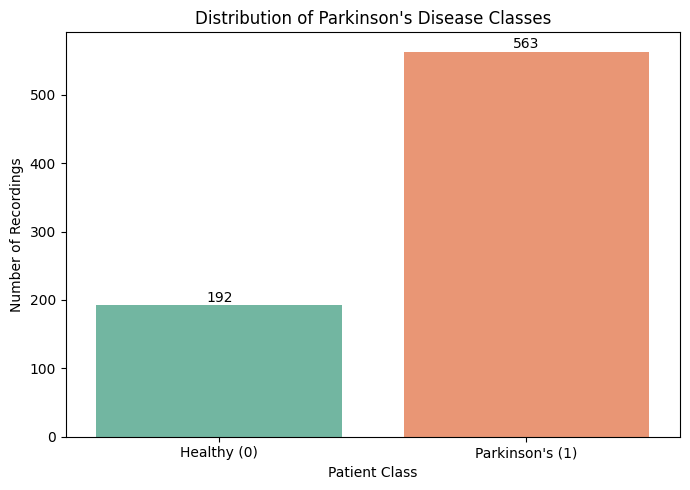

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
PPE,755.0,0.746225,0.169398,0.041551,0.762765,0.80973,0.834400,0.90766
DFA,755.0,0.700567,0.069637,0.543500,0.647335,0.70069,0.754990,0.85264
RPDE,755.0,0.488854,0.137420,0.154300,0.386325,0.48410,0.585545,0.87123



Total prediction features: 753
Constant features: 0
Constant feature names: []


In [6]:
# Visualize target class distribution

class_counts = df_clean["class"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Healthy (0)", "Parkinson's (1)"],
    y=class_counts.values,
    hue=["Healthy (0)", "Parkinson's (1)"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Parkinson's Disease Classes")
plt.xlabel("Patient Class")
plt.ylabel("Number of Recordings")

for i, count in enumerate(class_counts.values):
    plt.text(i, count + 5, str(count), ha="center")

plt.tight_layout()
plt.show()

# Descriptive statistics of selected voice features
print("Descriptive Statistics:")
display(df_clean[["PPE", "DFA", "RPDE"]].describe().T)

# Check features with constant values
feature_columns = df_clean.columns.drop(["id", "class"])

constant_features = [
    col for col in feature_columns
    if df_clean[col].nunique() <= 1
]

print("\nTotal prediction features:", len(feature_columns))
print("Constant features:", len(constant_features))
print("Constant feature names:", constant_features)

## Question 2: Training and Testing Data Split (1 Mark)

**Question:** Use 80% of samples as training data size.

The dataset is divided into approximately 80% training data and 20% testing data.

A patient-aware stratified split is performed because multiple recordings belong to the same patient.

This approach:
1. Prevents patient-level data leakage.
2. Preserves approximately the same class distribution.
3. Uses a fixed random state for reproducibility.

The patient ID and target class are excluded from the prediction features.

In [7]:
# Question 2: Patient-aware 80/20 train-test split

from sklearn.model_selection import train_test_split

# Create one record per patient for stratified splitting
patient_labels = (
    df_clean.groupby("id", as_index=False)["class"]
    .first()
)

# Split patient IDs into 80% training and 20% testing
train_ids, test_ids = train_test_split(
    patient_labels["id"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=patient_labels["class"]
)

# Select all recordings belonging to each patient group
train_df = df_clean[df_clean["id"].isin(train_ids)].copy()
test_df = df_clean[df_clean["id"].isin(test_ids)].copy()

# Separate features and target labels
X_train = train_df.drop(columns=["id", "class"])
X_test = test_df.drop(columns=["id", "class"])

y_train = train_df["class"]
y_test = test_df["class"]

# Display dataset dimensions
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

# Display split percentages
print("\nTraining percentage:",
      round(len(X_train) / len(df_clean) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(df_clean) * 100, 2), "%")

# Verify that patients do not overlap
overlap = set(train_ids).intersection(set(test_ids))

print("\nTraining patients:", len(train_ids))
print("Testing patients:", len(test_ids))
print("Overlapping patient IDs:", len(overlap))

# Display class distributions
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

# Validate the split
assert len(overlap) == 0, "Patient data leakage detected!"
assert len(X_train) + len(X_test) == len(df_clean)
assert X_train.shape[1] == X_test.shape[1] == 753

print("\nPatient-aware train-test split completed successfully!")

Training features shape: (602, 753)
Testing features shape: (153, 753)

Training labels shape: (602,)
Testing labels shape: (153,)

Training percentage: 79.74 %
Testing percentage: 20.26 %

Training patients: 201
Testing patients: 51
Overlapping patient IDs: 0

Training class distribution:
class
0    153
1    449
Name: count, dtype: int64

Testing class distribution:
class
0     39
1    114
Name: count, dtype: int64

Patient-aware train-test split completed successfully!


### Question 1 (Continued): Data Standardization

The Parkinson's disease dataset contains 753 prediction features with different numerical scales.

StandardScaler is applied to standardize the features.

To prevent data leakage:
1. The scaler is fitted only on the training data.
2. The same fitted scaler transforms the testing data.
3. The target variable and patient IDs are excluded from standardization.

Standardization is particularly important for distance-based models such as KNN and SVM.

In [8]:
# Question 1: Data Standardization

from sklearn.preprocessing import StandardScaler

# Initialize the standard scaler
scaler = StandardScaler()

# Fit the scaler on training data only
# Transform both training and testing features
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify dataset dimensions
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

# Check standardized training feature statistics
print("\nFirst 5 training feature means:")
print(X_train_scaled.mean().head().round(6))

print("\nFirst 5 training feature standard deviations:")
print(X_train_scaled.std(ddof=0).head().round(6))

# Compare original and standardized feature values
print("\nOriginal training features (first 5 columns):")
display(X_train.iloc[:5, :5])

print("\nStandardized training features (first 5 columns):")
display(X_train_scaled.iloc[:5, :5])

# Verify no missing values were introduced
print("\nMissing values in scaled training data:",
      X_train_scaled.isna().sum().sum())

print("Missing values in scaled testing data:",
      X_test_scaled.isna().sum().sum())

# Verify dimensions
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape

print("\nData standardization completed successfully!")

Training data shape: (602, 753)
Testing data shape: (153, 753)

First 5 training feature means:
gender      -0.0
PPE          0.0
DFA         -0.0
RPDE        -0.0
numPulses   -0.0
dtype: float64

First 5 training feature standard deviations:
gender       1.0
PPE          1.0
DFA          1.0
RPDE         1.0
numPulses    1.0
dtype: float64

Original training features (first 5 columns):


,gender,PPE,DFA,RPDE,numPulses
0,1,0.85247,0.71826,0.57227,240
1,1,0.76686,0.69481,0.53966,234
2,1,0.85083,0.67604,0.58982,232
6,1,0.76095,0.62145,0.54543,322
7,1,0.83671,0.62079,0.51179,318



Standardized training features (first 5 columns):


,gender,PPE,DFA,RPDE,numPulses
0,0.907878,0.606642,0.262304,0.622647,-0.832589
1,0.907878,0.092929,-0.070681,0.388243,-0.891956
2,0.907878,0.596801,-0.337211,0.748798,-0.911745
6,0.907878,0.057465,-1.112378,0.429718,-0.021235
7,0.907878,0.512072,-1.121750,0.187910,-0.060814



Missing values in scaled training data: 0
Missing values in scaled testing data: 0

Data standardization completed successfully!


## Question 3: Model Training (2 Marks)

**Question:** Use the following models to train the data:

1. K-Nearest Neighbors (KNN)
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree

Four supervised machine learning classification models are trained using the training dataset.

KNN and SVM use standardized training features because these algorithms are sensitive to feature scales.

Random Forest and Decision Tree use the original numerical features because tree-based models do not require feature standardization.

A fixed random state is used where applicable to ensure reproducible results.

In [9]:
# Question 3: Train four classification models

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

print("1. KNN model trained successfully!")

# 2. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)
rf_model.fit(X_train, y_train)

print("2. Random Forest model trained successfully!")

# 3. Support Vector Machine (SVM)
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)
svm_model.fit(X_train_scaled, y_train)

print("3. SVM model trained successfully!")

# 4. Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)
dt_model.fit(X_train, y_train)

print("4. Decision Tree model trained successfully!")

print("\nAll four classification models trained successfully!")

1. KNN model trained successfully!
2. Random Forest model trained successfully!
3. SVM model trained successfully!
4. Decision Tree model trained successfully!

All four classification models trained successfully!


## Question 4: Predict Classes on Test Data (2 Marks)

**Question:** Predict the class (patient's Parkinson's disease) on the test data for all the models.

The four trained classification models are used to predict Parkinson's disease on the unseen testing dataset.

The predictions are generated using:

1. K-Nearest Neighbors (KNN)
2. Random Forest
3. Support Vector Machine (SVM)
4. Decision Tree

KNN and SVM use standardized testing features, while Random Forest and Decision Tree use the original testing features.

**Target Classes:**
- 0 = Healthy
- 1 = Parkinson's Disease

The predicted classes are compared with the actual test labels in a single DataFrame.

In [10]:
# Question 4: Predict classes using all four trained models

# 1. K-Nearest Neighbors predictions
knn_predictions = knn_model.predict(X_test_scaled)

# 2. Random Forest predictions
rf_predictions = rf_model.predict(X_test)

# 3. Support Vector Machine predictions
svm_predictions = svm_model.predict(X_test_scaled)

# 4. Decision Tree predictions
dt_predictions = dt_model.predict(X_test)

# Combine actual and predicted labels in one DataFrame
prediction_results = pd.DataFrame({
    "Patient_ID": test_df["id"].to_numpy(),
    "Actual_Class": y_test.to_numpy(),
    "KNN_Prediction": knn_predictions,
    "Random_Forest_Prediction": rf_predictions,
    "SVM_Prediction": svm_predictions,
    "Decision_Tree_Prediction": dt_predictions
})

# Display first 10 predictions
print("Test Data Predictions (First 10 Records):")
display(prediction_results.head(10))

# Verify prediction counts
print("\nTotal test recordings:", len(y_test))
print("KNN predictions:", len(knn_predictions))
print("Random Forest predictions:", len(rf_predictions))
print("SVM predictions:", len(svm_predictions))
print("Decision Tree predictions:", len(dt_predictions))

# Verify that every model predicts valid class labels
prediction_columns = [
    "KNN_Prediction",
    "Random_Forest_Prediction",
    "SVM_Prediction",
    "Decision_Tree_Prediction"
]

assert len(prediction_results) == len(y_test)

for column in prediction_columns:
    assert prediction_results[column].isin([0, 1]).all()

print("\nAll four models generated valid predictions successfully!")

Test Data Predictions (First 10 Records):


,Patient_ID,Actual_Class,KNN_Prediction,Random_Forest_Prediction,SVM_Prediction,Decision_Tree_Prediction
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,0
3,3,1,1,1,1,1
4,3,1,1,1,1,1
5,3,1,0,1,1,1
6,8,1,1,1,1,1
7,8,1,0,1,1,1
8,8,1,0,1,1,1
9,15,1,1,1,1,1



Total test recordings: 153
KNN predictions: 153
Random Forest predictions: 153
SVM predictions: 153
Decision Tree predictions: 153

All four models generated valid predictions successfully!


## Question 5: Predictive System (1 Mark)

**Question:** Build a predictive system to verify that the models built can predict the patient's Parkinson's disease with a new sample.

A reusable prediction function is developed to classify a new voice recording using all four trained models.

The function:
1. Accepts a new sample containing the 753 prediction features.
2. Applies the previously fitted StandardScaler for KNN and SVM.
3. Uses the original features for Random Forest and Decision Tree.
4. Returns predictions from all four models.

**Class Labels:**
- 0 = Healthy
- 1 = Parkinson's Disease

A recording from the held-out test dataset is used to demonstrate the system because it was not included in model training.

These predictions are for educational purposes and are not a clinical diagnosis.

In [11]:
# Question 5: Build a predictive system

def predict_parkinsons(new_sample):
    """
    Predict Parkinson's disease using four trained classifiers.

    Parameters:
        new_sample: pandas DataFrame containing 753 features.

    Returns:
        DataFrame containing predictions from all four models.
    """

    # Validate input
    if not isinstance(new_sample, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    # Validate feature names
    missing = X_train.columns.difference(new_sample.columns)
    extra = new_sample.columns.difference(X_train.columns)

    if len(missing) > 0 or len(extra) > 0:
        raise ValueError(
            f"Feature mismatch: {len(missing)} missing, "
            f"{len(extra)} unexpected."
        )

    # Ensure correct feature order
    new_sample = new_sample.loc[:, X_train.columns]

    # Standardize using the existing training scaler
    scaled_sample = pd.DataFrame(
        scaler.transform(new_sample),
        columns=X_train.columns,
        index=new_sample.index
    )

    # Generate predictions from all four models
    results = pd.DataFrame({
        "KNN": knn_model.predict(scaled_sample),
        "Random_Forest": rf_model.predict(new_sample),
        "SVM": svm_model.predict(scaled_sample),
        "Decision_Tree": dt_model.predict(new_sample)
    }, index=new_sample.index)

    return results


# Demonstrate with a recording not used during training
new_sample = X_test.iloc[[0]].copy()

# Predict using the system
new_predictions = predict_parkinsons(new_sample)

print("Predictions for a new sample:")
display(new_predictions)

# Compare with known label for verification
print("Actual Class:", y_test.loc[new_sample.index[0]])

print("\nPredictive system executed successfully!")

Predictions for a new sample:


,KNN,Random_Forest,SVM,Decision_Tree
3,1,1,1,1


Actual Class: 1

Predictive system executed successfully!


## Question 6: Model Evaluation and Comparison (2 Marks)

**Question:** Measure model accuracies and find the best model (highest accuracy). Also, find confusion matrix and classification report for all models. Summarize the final outputs of these evaluation matrices.

The four classification models are evaluated using the held-out testing dataset.

The following evaluation metrics are calculated:

1. **Accuracy:** Percentage of correctly classified recordings.
2. **Precision:** Proportion of predicted positive recordings that are actually positive.
3. **Recall:** Proportion of actual positive recordings correctly identified.
4. **F1-Score:** Harmonic mean of precision and recall.
5. **Confusion Matrix:** Shows true negatives, false positives, false negatives, and true positives.
6. **Classification Report:** Provides precision, recall, F1-score, and support for each class.

The best-performing model is selected based on the highest testing accuracy, as required by the assignment.

Because the dataset is imbalanced, precision, recall, and F1-score are also considered when interpreting results.

In [12]:
# Question 6: Evaluate all four classification models

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Store predictions from all models
model_predictions = {
    "KNN": knn_predictions,
    "Random Forest": rf_predictions,
    "SVM": svm_predictions,
    "Decision Tree": dt_predictions
}

# Store evaluation results
evaluation_records = []
confusion_matrices = {}
classification_reports = {}

# Evaluate each model
for model_name, predictions in model_predictions.items():

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    confusion_matrices[model_name] = cm

    # Generate classification report
    report = classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Healthy", "Parkinson's"],
        zero_division=0,
        output_dict=True
    )

    classification_reports[model_name] = report

    # Store evaluation metrics
    evaluation_records.append({
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": report["Parkinson's"]["precision"] * 100,
        "Recall (%)": report["Parkinson's"]["recall"] * 100,
        "F1-Score (%)": report["Parkinson's"]["f1-score"] * 100
    })

    # Display individual model results
    print("=" * 60)
    print(f"MODEL: {model_name}")
    print("=" * 60)

    print(f"\nAccuracy: {accuracy * 100:.2f}%")

    print("\nConfusion Matrix:")
    display(pd.DataFrame(
        cm,
        index=["Actual Healthy", "Actual Parkinson's"],
        columns=["Predicted Healthy", "Predicted Parkinson's"]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Healthy", "Parkinson's"],
        zero_division=0
    ))

# Create comparison table
evaluation_summary = pd.DataFrame(evaluation_records)

# Sort by highest accuracy
evaluation_summary = evaluation_summary.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

display(evaluation_summary.round(2))

# Identify best model based on highest accuracy
best_accuracy = evaluation_summary["Accuracy (%)"].max()

best_models = evaluation_summary.loc[
    np.isclose(evaluation_summary["Accuracy (%)"], best_accuracy),
    "Model"
].tolist()

print("\nBest model(s) based on accuracy:", ", ".join(best_models))
print(f"Highest test accuracy: {best_accuracy:.2f}%")

# Calculate majority-class baseline
baseline_accuracy = y_test.value_counts().max() / len(y_test) * 100

print(f"\nMajority-class baseline accuracy: {baseline_accuracy:.2f}%")
print("\nModel evaluation completed successfully!")

MODEL: KNN

Accuracy: 75.16%

Confusion Matrix:


,Predicted Healthy,Predicted Parkinson's
Actual Healthy,14,25
Actual Parkinson's,13,101



Classification Report:
              precision    recall  f1-score   support

     Healthy       0.52      0.36      0.42        39
 Parkinson's       0.80      0.89      0.84       114

    accuracy                           0.75       153
   macro avg       0.66      0.62      0.63       153
weighted avg       0.73      0.75      0.74       153

MODEL: Random Forest

Accuracy: 80.39%

Confusion Matrix:


,Predicted Healthy,Predicted Parkinson's
Actual Healthy,15,24
Actual Parkinson's,6,108



Classification Report:
              precision    recall  f1-score   support

     Healthy       0.71      0.38      0.50        39
 Parkinson's       0.82      0.95      0.88       114

    accuracy                           0.80       153
   macro avg       0.77      0.67      0.69       153
weighted avg       0.79      0.80      0.78       153

MODEL: SVM

Accuracy: 80.39%

Confusion Matrix:


,Predicted Healthy,Predicted Parkinson's
Actual Healthy,14,25
Actual Parkinson's,5,109



Classification Report:
              precision    recall  f1-score   support

     Healthy       0.74      0.36      0.48        39
 Parkinson's       0.81      0.96      0.88       114

    accuracy                           0.80       153
   macro avg       0.78      0.66      0.68       153
weighted avg       0.79      0.80      0.78       153

MODEL: Decision Tree

Accuracy: 73.20%

Confusion Matrix:


,Predicted Healthy,Predicted Parkinson's
Actual Healthy,16,23
Actual Parkinson's,18,96



Classification Report:
              precision    recall  f1-score   support

     Healthy       0.47      0.41      0.44        39
 Parkinson's       0.81      0.84      0.82       114

    accuracy                           0.73       153
   macro avg       0.64      0.63      0.63       153
weighted avg       0.72      0.73      0.73       153


FINAL MODEL COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Random Forest,80.39,81.82,94.74,87.80
1,SVM,80.39,81.34,95.61,87.90
2,KNN,75.16,80.16,88.60,84.17
3,Decision Tree,73.20,80.67,84.21,82.40



Best model(s) based on accuracy: Random Forest, SVM
Highest test accuracy: 80.39%

Majority-class baseline accuracy: 74.51%

Model evaluation completed successfully!


### 6.1 Confusion Matrix Visualization

The confusion matrices for all four classification models are visualized to compare their prediction performance.

Each confusion matrix shows:

- True Negatives (TN): Healthy recordings correctly classified.
- False Positives (FP): Healthy recordings incorrectly classified as Parkinson's.
- False Negatives (FN): Parkinson's recordings incorrectly classified as healthy.
- True Positives (TP): Parkinson's recordings correctly classified.

These visualizations help identify the types of classification errors made by each model.

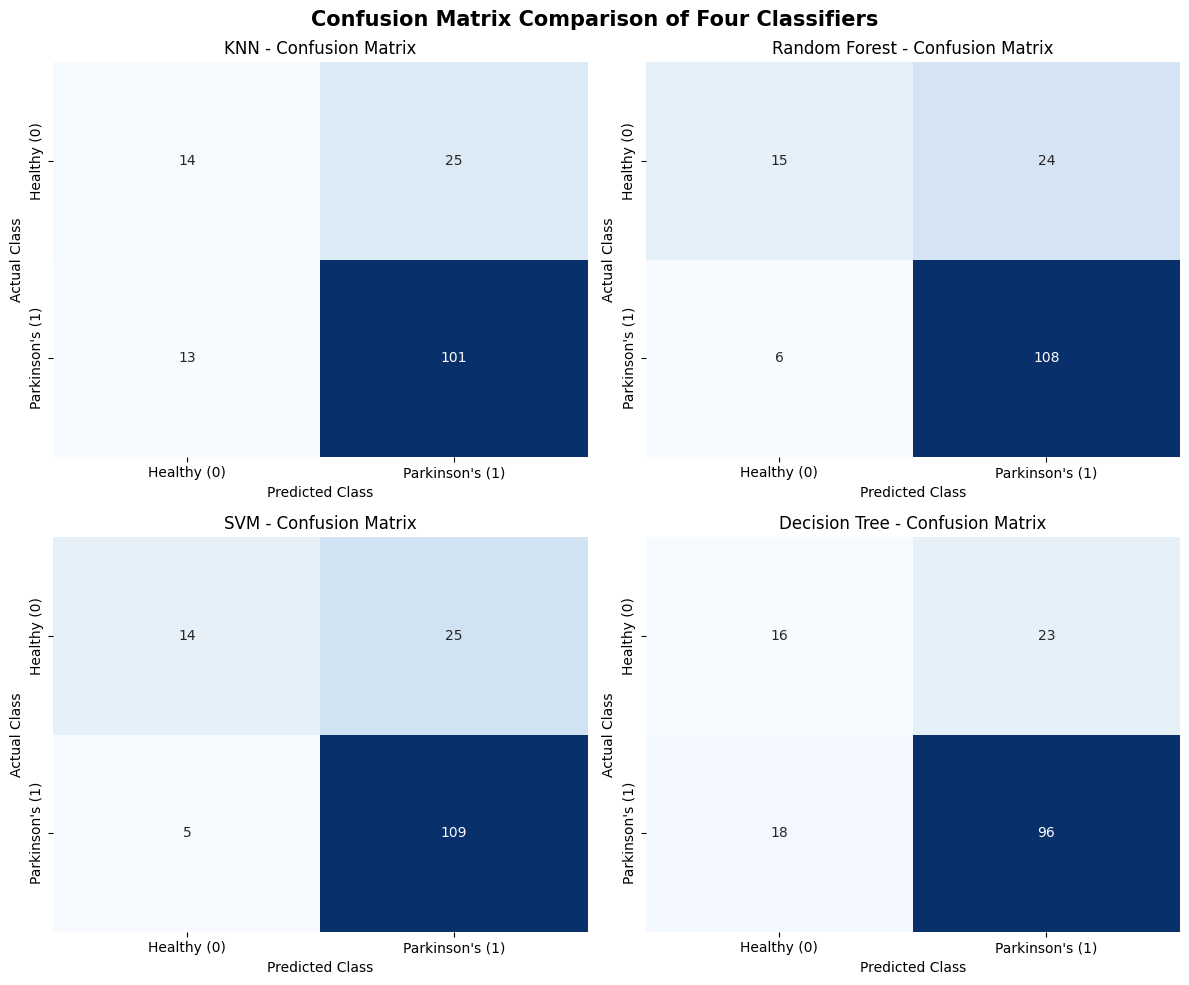

In [13]:
# Question 6: Visualize confusion matrices for all models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, cm) in zip(
    axes.flat,
    confusion_matrices.items()
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Healthy (0)", "Parkinson's (1)"],
        yticklabels=["Healthy (0)", "Parkinson's (1)"],
        ax=ax
    )

    ax.set_title(f"{model_name} - Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison of Four Classifiers",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 6.2 Final Model Evaluation Summary and Discussion

#### Model Accuracy Comparison

Four machine learning classification models were evaluated using 153 unseen test recordings from patients excluded from the training dataset.

| Model | Accuracy | Precision (Class 1) | Recall (Class 1) | F1-Score (Class 1) |
|---|---:|---:|---:|---:|
| Random Forest | 80.39% | 81.82% | 94.74% | 87.80% |
| SVM | 80.39% | 81.34% | 95.61% | 87.90% |
| KNN | 75.16% | 80.16% | 88.60% | 84.17% |
| Decision Tree | 73.20% | 80.67% | 84.21% | 82.40% |

#### Confusion Matrix Interpretation

**1. K-Nearest Neighbors (KNN)**

KNN correctly classified 115 out of 153 test recordings, achieving 75.16% accuracy. It produced 14 true negatives, 101 true positives, 25 false positives, and 13 false negatives.

**2. Random Forest**

Random Forest correctly classified 123 out of 153 test recordings, achieving 80.39% accuracy. It produced 15 true negatives, 108 true positives, 24 false positives, and 6 false negatives. Random Forest achieved the highest accuracy, tied with SVM.

**3. Support Vector Machine (SVM)**

SVM also correctly classified 123 out of 153 test recordings, achieving 80.39% accuracy. It produced 14 true negatives, 109 true positives, 25 false positives, and 5 false negatives.

SVM achieved the highest Parkinson's disease recall (95.61%) and the fewest false negatives among the four models.

**4. Decision Tree**

Decision Tree correctly classified 112 out of 153 test recordings, achieving 73.20% accuracy. It produced 16 true negatives, 96 true positives, 23 false positives, and 18 false negatives.

Decision Tree had the lowest accuracy and the highest number of false negatives.

#### Best Model Selection

According to the assignment requirement to select the model with the highest accuracy, **Random Forest and SVM are tied as the best-performing models**, both achieving 80.39%.

If an additional selection criterion is required, SVM has a slight advantage for identifying Parkinson's disease because it achieves higher recall (95.61% versus 94.74%) and produces fewer false negatives.

However, Random Forest correctly identifies slightly more healthy recordings.

#### Limitations and Observations

The dataset is imbalanced, containing approximately 74.57% Parkinson's disease recordings. The majority-class baseline accuracy on the test set is 74.51%.

Therefore, accuracy alone is insufficient to fully assess model performance.

All four models show relatively low recall for healthy recordings, indicating difficulties distinguishing healthy individuals from patients with Parkinson's disease.

A patient-aware train-test split was used to prevent recordings from the same individual appearing in both datasets.

These results demonstrate performance on the selected test recordings and should not be interpreted as evidence that the models are suitable for clinical diagnosis.

#### Final Conclusion

Random Forest and SVM achieved the best classification accuracy of 80.39%. SVM also achieved the highest recall for Parkinson's disease at 95.61%.

Both models performed better than KNN and Decision Tree in terms of accuracy. However, additional validation, improved class balance handling, and further model evaluation would be necessary before considering practical medical applications.

## Question 7: Export Test Predictions to CSV (1 Mark)

**Question:** Save the test data predictions for all the models as a single CSV file.

The predictions generated by KNN, Random Forest, SVM, and Decision Tree are saved into one CSV file.

The CSV includes:

1. Patient ID
2. Actual class
3. KNN prediction
4. Random Forest prediction
5. SVM prediction
6. Decision Tree prediction

Each row represents one test recording.

The exported file is validated to ensure all 153 test recordings and their corresponding predictions are saved correctly.

In [14]:
# Question 7: Export all model predictions to a single CSV file

from pathlib import Path

# Define output filename
output_path = Path("Ubaid_Ullah_Assignment_1_Predictions.csv")

# Export predictions from Question 4
prediction_results.to_csv(output_path, index=False)

print("CSV file created successfully!")
print("Filename:", output_path.name)

# Read the exported CSV to verify its contents
saved_predictions = pd.read_csv(output_path)

print("\nSaved CSV shape:", saved_predictions.shape)
print("Total saved recordings:", len(saved_predictions))

print("\nFirst 10 rows of the exported CSV:")
display(saved_predictions.head(10))

# Validate exported predictions
assert saved_predictions.shape == (153, 6)
assert saved_predictions.isnull().sum().sum() == 0

# Verify exported data matches original predictions
pd.testing.assert_frame_equal(
    saved_predictions.reset_index(drop=True),
    prediction_results.reset_index(drop=True)
)

# Confirm all prediction columns contain valid classes
for column in prediction_columns:
    assert saved_predictions[column].isin([0, 1]).all()

print("\nCSV validation passed!")
print("All four model predictions saved correctly.")
print("File location:", output_path.resolve())

CSV file created successfully!
Filename: Ubaid_Ullah_Assignment_1_Predictions.csv

Saved CSV shape: (153, 6)
Total saved recordings: 153

First 10 rows of the exported CSV:


,Patient_ID,Actual_Class,KNN_Prediction,Random_Forest_Prediction,SVM_Prediction,Decision_Tree_Prediction
0,1,1,1,1,1,1
1,1,1,1,1,1,1
2,1,1,1,1,1,0
3,3,1,1,1,1,1
4,3,1,1,1,1,1
5,3,1,0,1,1,1
6,8,1,1,1,1,1
7,8,1,0,1,1,1
8,8,1,0,1,1,1
9,15,1,1,1,1,1



CSV validation passed!
All four model predictions saved correctly.
File location: C:\Users\Ubaid\Downloads\CSCN8000_Assignment_1\Ubaid_Ullah_Assignment_1_Predictions.csv
